# US Public Pre-K and Kindergarten by State, 2010-2022: Starter Notebook

![cover](https://raw.githubusercontent.com/montessoritheory/us-public-prek-kindergarten/main/images/cover.png)

Public school enrollment by grade for the 50 states and DC, every fall from 2010 to 2022 (NCES Common Core of Data, via the Digest of Education Statistics), and the share of 3- to 5-year-olds enrolled in school by state (Census ACS, 2021 to 2023).

Dataset by [Montessori Theory](https://www.montessori-theory.com/), CC BY 4.0.

In [1]:
import os, glob, pandas as pd, matplotlib.pyplot as plt

GITHUB = 'https://raw.githubusercontent.com/montessoritheory/us-public-prek-kindergarten/main/data'
hits = glob.glob('/kaggle/input/**/prek_and_kindergarten_by_state.csv', recursive=True)
BASE = os.path.dirname(hits[0]) if hits else next((p for p in ['data', '../data'] if os.path.exists(f'{p}/prek_and_kindergarten_by_state.csv')), GITHUB)
pk = pd.read_csv(f'{BASE}/prek_and_kindergarten_by_state.csv')
en = pd.read_csv(f'{BASE}/public_enrollment_by_state_and_grade_2010_2022.csv')
rate = pd.read_csv(f'{BASE}/children_3_to_5_enrolled_by_state_2021_2023.csv')
plt.rcParams.update({'figure.facecolor': '#F7F3EC', 'axes.facecolor': '#F7F3EC', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#E4DED3', 'font.size': 12})
TC, BLUE = '#B4532F', '#1F72B8'
pk.head()

,fall_year,state,state_abbr,prekindergarten,kindergarten,total_all_grades,source_note,prek_per_100_kindergartners,prek_share_of_enrollment_pct,prek_change_since_2012_pct
0,2010,Alabama,AL,8179,57665,755552,NaN,14.2,1.08,-9.4
1,2010,Alaska,AK,2990,10120,132104,NaN,29.5,2.26,-4.5
2,2010,Arizona,AZ,8554,82860,1071751,NaN,10.3,0.80,-8.1
3,2010,Arkansas,AR,14059,37701,482114,NaN,37.3,2.92,-1.6
4,2010,California,CA,72404,468036,6289578,NaN,15.5,1.15,-2.6


## 1. The national trend

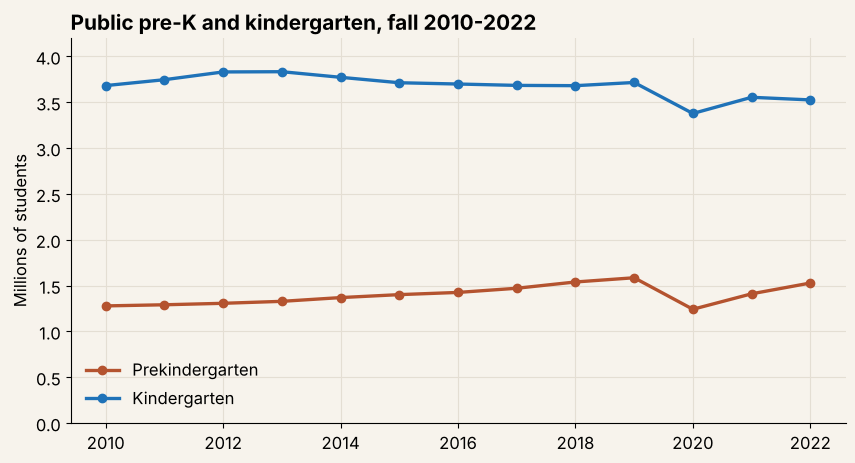

In [2]:
us = pk[pk.state == 'United States']
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(us.fall_year, us.prekindergarten / 1e6, marker='o', color=TC, lw=2.4, label='Prekindergarten')
ax.plot(us.fall_year, us.kindergarten / 1e6, marker='o', color=BLUE, lw=2.4, label='Kindergarten')
ax.set_ylim(0, 4.2); ax.set_ylabel('Millions of students'); ax.legend(frameon=False)
ax.set_title('Public pre-K and kindergarten, fall 2010-2022', loc='left', fontsize=15, fontweight='bold'); plt.show()

## 2. States compared

Pre-K students per 100 kindergartners compares the size of public pre-K systems. Some states count both 3- and 4-year-olds, so values above 100 are possible.

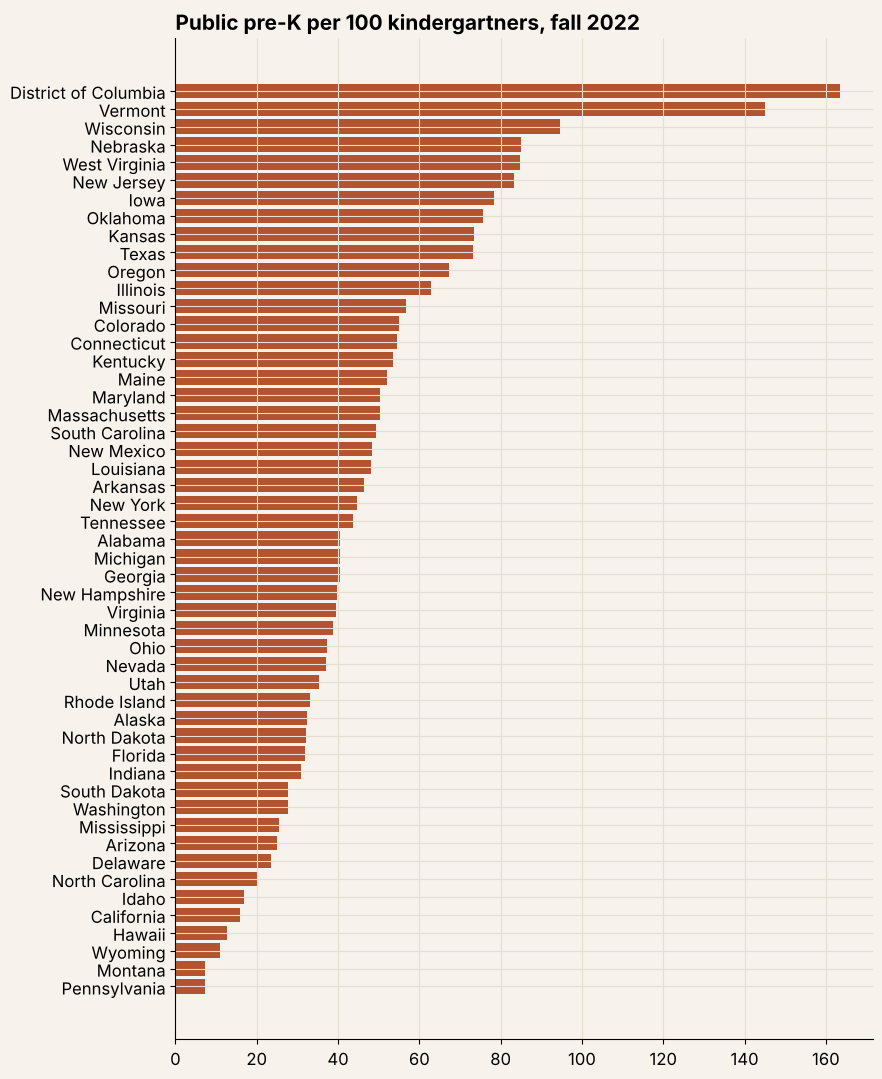

In [3]:
l = pk[(pk.fall_year == 2022) & (pk.state != 'United States')].sort_values('prek_per_100_kindergartners')
fig, ax = plt.subplots(figsize=(9, 13)); ax.barh(l.state, l.prek_per_100_kindergartners, color=TC)
ax.set_title('Public pre-K per 100 kindergartners, fall 2022', loc='left', fontsize=15, fontweight='bold'); plt.show()

In [4]:
growth = pk[(pk.fall_year == 2022) & (pk.state != 'United States')].sort_values('prek_change_since_2012_pct', ascending=False)
growth[['state', 'prekindergarten', 'prek_change_since_2012_pct']].head(10)

,state,prekindergarten,prek_change_since_2012_pct
652,Nevada,11858,157.8
624,Alabama,23238,157.3
638,Indiana,22798,150.1
648,Mississippi,8340,107.2
654,New Jersey,71749,104.3
626,Arizona,18982,104.0
631,Delaware,2282,76.8
672,Washington,21595,73.2
647,Minnesota,23827,62.1
659,Ohio,44585,61.8


## 3. Young children in school, by state

In [5]:
r = rate[rate.year == 2023].sort_values('percent_enrolled_in_school', ascending=False)
r[['state', 'percent_enrolled_in_school', 'standard_error']].head(10)

,state,percent_enrolled_in_school,standard_error
112,District of Columbia,94.4,2.10
110,Connecticut,76.0,1.85
150,Vermont,75.4,4.97
136,New York,75.1,0.78
134,New Jersey,74.6,1.09
155,Wyoming,70.5,5.20
125,Massachusetts,67.0,1.44
117,Illinois,64.8,0.90
122,Louisiana,64.4,1.68
120,Kansas,64.0,2.02


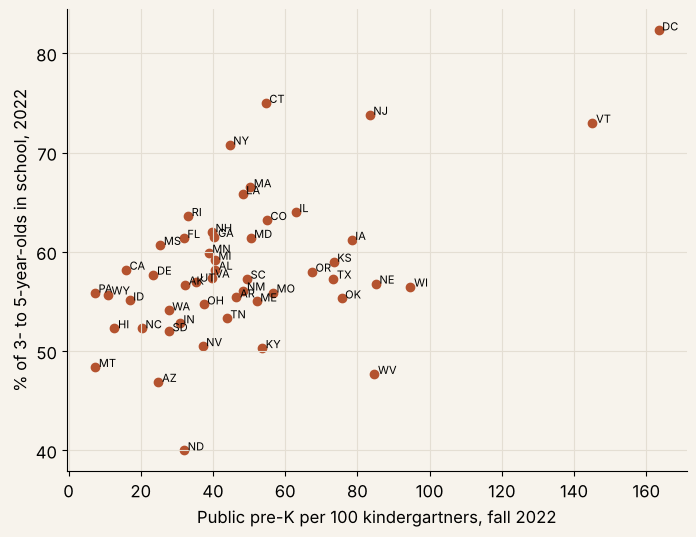

In [6]:
m = pk[pk.fall_year == 2022].merge(rate[rate.year == 2022], on='state')
m = m[m.state != 'United States']
fig, ax = plt.subplots(figsize=(8, 6)); ax.scatter(m.prek_per_100_kindergartners, m.percent_enrolled_in_school, color=TC)
for _, row in m.iterrows(): ax.text(row.prek_per_100_kindergartners + 1, row.percent_enrolled_in_school, row.state_abbr_x, fontsize=8)
ax.set_xlabel('Public pre-K per 100 kindergartners, fall 2022'); ax.set_ylabel('% of 3- to 5-year-olds in school, 2022'); plt.show()

## 4. Ideas to go further

- Use every grade in `public_enrollment_by_state_and_grade_2010_2022.csv` to follow cohorts from kindergarten to grade 12.
- Measure the size of the fall 2020 drop in kindergarten and how much came back, state by state.
- Join with state pre-K policy data to see which programs are delivered in public schools.

More on the Montessori kindergarten year: [Montessori Theory](https://www.montessori-theory.com/montessori-kindergarten-approach/).